# Import dependencies

In [14]:

import numpy as np
import copy
import matplotlib.pyplot as plt
import sklearn
import sklearn.datasets
import sklearn.linear_model

 # Define dataset

In [15]:
def load_planar_dataset():
    np.random.seed(1)
    m = 400 # number of examples
    N = int(m/2) # number of points per class
    D = 2 # dimensionality
    X = np.zeros((m,D)) # data matrix where each row is a single example
    Y = np.zeros((m,1), dtype='uint8') # labels vector (0 for red, 1 for blue)
    a = 4 # maximum ray of the flower

    for j in range(2):
        ix = range(N*j,N*(j+1))
        t = np.linspace(j*3.12,(j+1)*3.12,N) + np.random.randn(N)*0.2 # theta
        r = a*np.sin(4*t) + np.random.randn(N)*0.2 # radius
        X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
        Y[ix] = j
        
    X = X.T
    Y = Y.T

    return X, Y

# Load dataset

In [16]:
X, Y = load_planar_dataset()

# Visualize the data

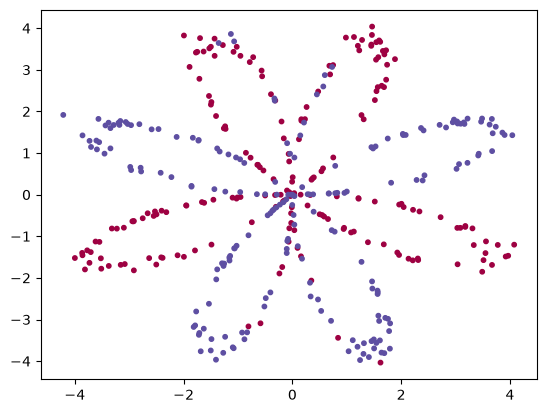

In [17]:
plt.scatter(X[0, :], X[1, :], c=Y, s=10, cmap=plt.cm.Spectral);

In [18]:
print ('The shape of X is: ', X.shape)
print ('The shape of Y is: ', Y.shape)
print('I have m = %d training examples!' % (X.shape[1]))

The shape of X is:  (2, 400)
The shape of Y is:  (1, 400)
I have m = 400 training examples!


# Define the hidden layer size

In [19]:
hidden_layer_nodes = 4

def layer_sizes(X, Y):
    n_x = X.shape[0]
    n_h = hidden_layer_nodes
    n_y = Y.shape[0]

    return (n_x, n_h, n_y)

# Define activation function

In [20]:
def sigmoid(x):
    
    s = 1/(1+np.exp(-x))
    return s

# Define function for parameter (weight and bias) initialization

In [21]:
def initialize_parameters(n_x, n_h, n_y):
    
    np.random.seed(2)

    W1 = np.random.randn(n_h,n_x) * 0.01
    b1 = np.zeros((n_h,1))
    
    W2 = np.random.randn(n_y,n_h) * 0.01
    b2 = np.zeros((n_y,1))

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

In [22]:
n_x, n_h, n_y = layer_sizes(X, Y)
print('layer size:', n_x, n_h, n_y)
params = initialize_parameters(n_x, n_h, n_y)
for k, v in params.items():
    print(k, v.shape)
print(params["W1"])

layer size: 2 4 1
W1 (4, 2)
b1 (4, 1)
W2 (1, 4)
b2 (1, 1)
[[-0.00416758 -0.00056267]
 [-0.02136196  0.01640271]
 [-0.01793436 -0.00841747]
 [ 0.00502881 -0.01245288]]


# Forward propagation

In [23]:

def forward_propagation(X, parameters):
    
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]
    
    Z1 = np.dot(W1,X) + b1
    A1 = np.tanh(Z1)
    
    Z2 = np.dot(W2,A1) + b2
    A2 = sigmoid(Z2)
    
    cache = {"Z1": Z1,
             "A1": A1,
             "Z2": Z2,
             "A2": A2}
    
    return A2, cache

# Compute cost

In [24]:
def compute_cost(A2, Y):
    m = Y.shape[1]
    logprobs = np.multiply(Y, np.log(A2)) + np.multiply((1 - Y), np.log(1 - A2))
    cost = - np.multiply(1/m, np.sum(logprobs))
    cost = float(np.squeeze(cost))
    return cost

# Backward propagation

In [25]:
def backward_propagation(parameters, cache, X, Y):

    m = X.shape[1]
    W1 = parameters["W1"]
    W2 = parameters["W2"]
    
    A1 = cache["A1"]
    A2 = cache["A2"]

    dZ2 = A2 - Y
    dW2 = np.multiply(1/m, np.dot(dZ2, np.transpose(A1)))
    db2 = np.multiply(1/m, np.sum(dZ2, axis = 1, keepdims = True))
    dZ1 = np.multiply(np.dot(np.transpose(W2), dZ2), (1 - np.power(A1, 2)))
    dW1 = np.multiply(1/m, np.dot(dZ1, np.transpose(X)))
    db1 = np.multiply(1/m, np.sum(dZ1, axis = 1, keepdims = True))
    
    grads = {"dW1": dW1,
             "db1": db1,
             "dW2": dW2,
             "db2": db2}
    
    return grads


# Update parameters

In [26]:

def update_parameters(parameters, grads, learning_rate = 1.2):
    
    W1 = copy.deepcopy(parameters["W1"]) 
    b1 = copy.deepcopy(parameters["b1"]) 
    W2 = copy.deepcopy(parameters["W2"]) 
    b2 = copy.deepcopy(parameters["b2"]) 
    
    dW1 = copy.deepcopy(grads["dW1"]) 
    db1 = copy.deepcopy(grads["db1"])
    dW2 = copy.deepcopy(grads["dW2"])
    db2 = copy.deepcopy(grads["db2"])
    
    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1
    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

# Full NN model

In [27]:

def nn_model(X, Y, n_h, num_iterations = 10000, print_cost=False):
    
    np.random.seed(3)
    n_x = layer_sizes(X, Y)[0]
    n_y = layer_sizes(X, Y)[2]
    
    parameters = initialize_parameters(n_x, n_h, n_y)
   
    for i in range(0, num_iterations):
        
        A2, cache = forward_propagation(X, parameters)
        cost = compute_cost(A2, Y)
        grads = backward_propagation(parameters, cache, X, Y)
        parameters = update_parameters(parameters, grads, learning_rate = 1.2)
        
        # Print the cost every 1000 iterations
        if print_cost and i % 1000 == 0:
            print ("Cost after iteration %i: %f" %(i, cost))

    return parameters

# Test on our dataset

In [28]:
parameters = nn_model(X, Y, n_h = 4, num_iterations = 100000, print_cost=True)

Cost after iteration 0: 0.693048
Cost after iteration 1000: 0.288083
Cost after iteration 2000: 0.254385
Cost after iteration 3000: 0.233864
Cost after iteration 4000: 0.226792
Cost after iteration 5000: 0.222644
Cost after iteration 6000: 0.219731
Cost after iteration 7000: 0.217504
Cost after iteration 8000: 0.219447
Cost after iteration 9000: 0.218605
Cost after iteration 10000: 0.217904
Cost after iteration 11000: 0.217301
Cost after iteration 12000: 0.216780
Cost after iteration 13000: 0.216325
Cost after iteration 14000: 0.215921
Cost after iteration 15000: 0.215559
Cost after iteration 16000: 0.215231
Cost after iteration 17000: 0.214932
Cost after iteration 18000: 0.214658
Cost after iteration 19000: 0.214404
Cost after iteration 20000: 0.214169
Cost after iteration 21000: 0.213949
Cost after iteration 22000: 0.213744
Cost after iteration 23000: 0.213551
Cost after iteration 24000: 0.213369
Cost after iteration 25000: 0.213198
Cost after iteration 26000: 0.213035
Cost after ite

# Predict function

In [29]:
def predict(parameters, X):

    A2, cache = forward_propagation(X, parameters)
    predictions = (A2 > 0.5)

    return predictions

predictions = predict(parameters, X)
accuracy = np.mean(predictions == Y) * 100
print("Accuracy:", accuracy, "%")

Accuracy: 91.5 %


# Plot decision boundary

In [30]:
def plot_decision_boundary(model, X, y):
    # Set min and max values and give it some padding
    x_min, x_max = X[0, :].min() - 1, X[0, :].max() + 1
    y_min, y_max = X[1, :].min() - 1, X[1, :].max() + 1
    h = 0.01
    # Generate a grid of points with distance h between them
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    # Predict the function value for the whole grid
    Z = model(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    # Plot the contour and training examples
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, levels=np.linspace(0, 1, 6))
    plt.ylabel('x2')
    plt.xlabel('x1')
    plt.scatter(X[0, :], X[1, :], c=y, cmap=plt.cm.Spectral)

Text(0.5, 1.0, 'Decision Boundary for hidden layer size 4')

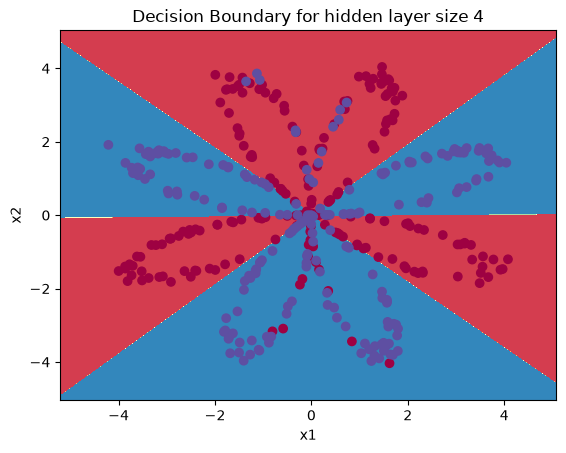

In [31]:
plot_decision_boundary(lambda x: predict(parameters, x.T), X, Y)
plt.title("Decision Boundary for hidden layer size 4")

# Tuning hidden layer size

Accuracy for 1 hidden units: 67.5 %
Accuracy for 2 hidden units: 67.25 %
Accuracy for 3 hidden units: 90.75 %
Accuracy for 4 hidden units: 90.5 %
Accuracy for 5 hidden units: 91.25 %
Accuracy for 10 hidden units: 90.25 %
Accuracy for 20 hidden units: 90.5 %
Accuracy for 50 hidden units: 90.75 %


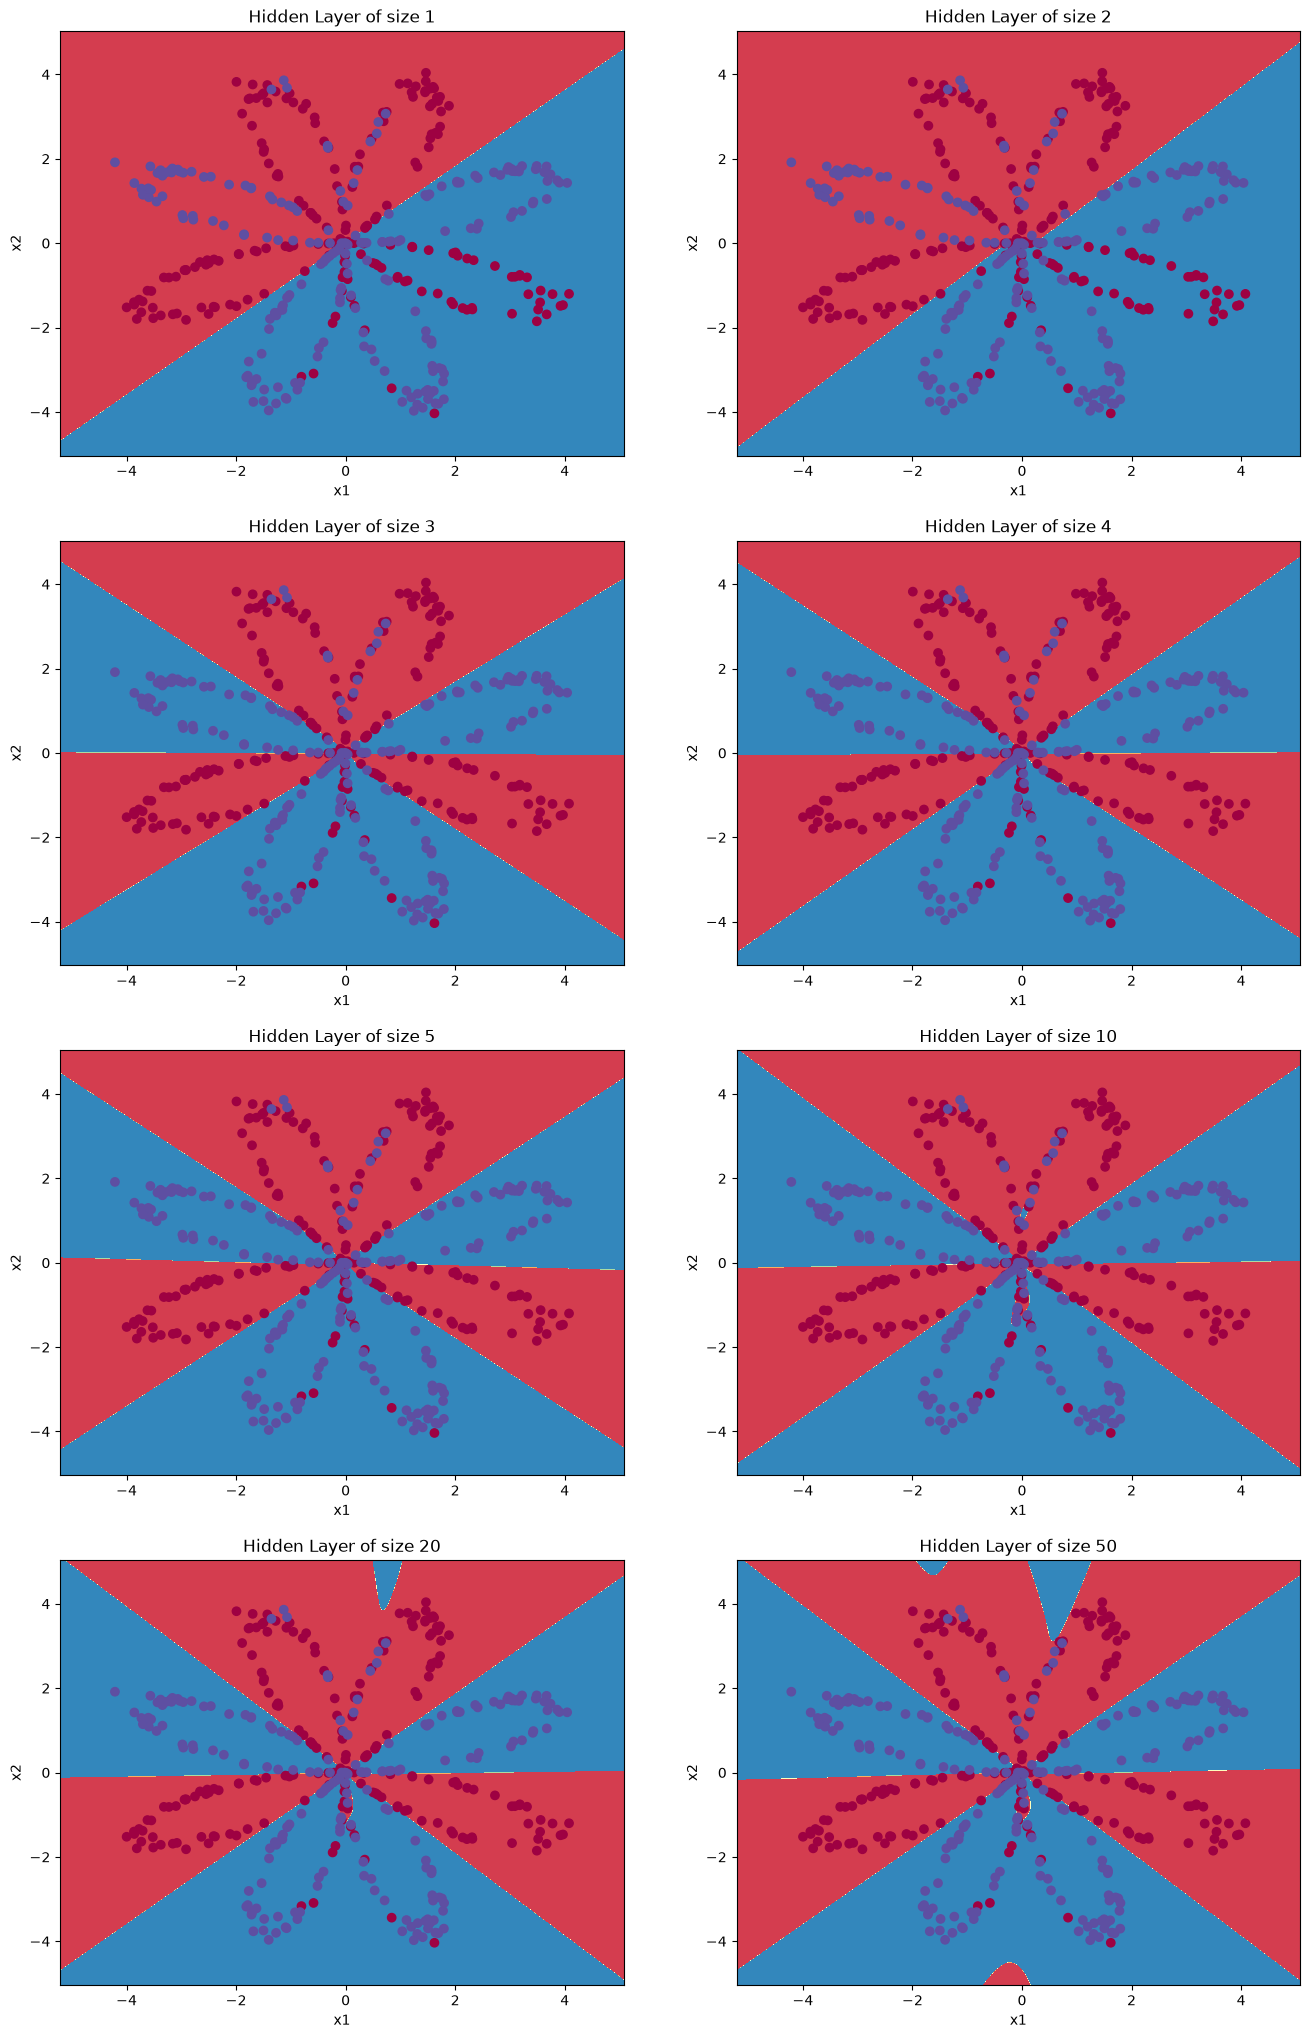

In [32]:
plt.figure(figsize=(16, 32))
hidden_layer_sizes = [1, 2, 3, 4, 5, 10, 20, 50]
for i, n_h in enumerate(hidden_layer_sizes):
    plt.subplot(5, 2, i+1)
    plt.title('Hidden Layer of size %d' % n_h)
    parameters = nn_model(X, Y, n_h, num_iterations = 5000)
    plot_decision_boundary(lambda x: predict(parameters, x.T), X, Y)
    predictions = predict(parameters, X)
    accuracy = ((np.dot(Y, predictions.T) + np.dot(1 - Y, 1 - predictions.T)) / float(Y.size) * 100).item()
    print ("Accuracy for {} hidden units: {} %".format(n_h, accuracy))

## Assignment: 
The notebook runs from top to bottom. I had to change the accuracy line, because float(np.dot(...)) gave a TypeError with NumPy 2.3.5, and I reordered a few cells so each one only uses things defined above it.

**Results with different hidden layer sizes (5000 iterations each)**

| Hidden units | 1 | 2 | 3 | 4 | 5 | 10 | 20 | 50 |
|---|---|---|---|---|---|---|---|---|
| Accuracy | 67.5% | 67.25% | 90.75% | 90.5% | 91.25% | 90.25% |90.5% | 90.75% |

With 4 hidden units and 100,000 iterations, the accuracy was 91.5%.

**What I noticed**
- 1 hidden unit gives a single straight line as the boundary, so it only gets about 67% right. 2 units were about the same.
- At 3 hidden units accuracy jumps to about 91%. The boundary becomes a set of wedges around the center that roughly follow the petals.
- After 3 units, more neurons don't help. 3, 4, 5, 10,20 and 50 units are all between 90% and 91%. The differences are only a few points out of 400, so I don't think they mean anything.
- With 20 and 50 units the boundary looks a bit more complicated (a few extra thin slices near the center and the edges), but the accuracy is not better.
- Training 4 units for 100,000 iterations instead of 5000 only gained about 1%. The cost curve flattens out after the first few thousand iterations.
- The remaining ~9% of errors are probably caused by the noise in the data, where red and blue points overlap.

**Conclusion**
A small hidden layer of 3 to 5 units is enough for this dataset. With fewer than 3 units the network is too simple, and with more than 5 it gets no better and just takes longer to train. I would pick 4 hidden units. One limit of this experiment is that I measured accuracy on the same data I trained on, so I can't tell if the bigger networks are overfitting. To check that, I would need a separate test set.